In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

## Dataset Description

In [3]:
df = pd.read_excel(r'C:\Users\Praveen\Downloads/Processed_Flipdata.xlsx')

In [4]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

In [5]:
display(df.head())
print("Dataset Shape:", df.shape)

,Model No,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Price
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


Dataset Shape: (541, 12)


## Data Exploration and Cleaning

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Model No       541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Price          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB


In [7]:
(df.isnull().sum())

Model No         0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Price            0
dtype: int64

In [8]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Model No,541.0,NaN,NaN,NaN,289.711645,182.359185,0.0,135.0,273.0,434.0,642.0
Model,541,187,realme C55,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Colour,541,275,Yellow,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,541.0,NaN,NaN,NaN,110.550832,60.600694,16.0,64.0,128.0,128.0,256.0
RAM,541.0,NaN,NaN,NaN,5.397412,1.984923,2.0,4.0,6.0,8.0,8.0
Battery_,541.0,NaN,NaN,NaN,4871.5878,780.148862,800.0,5000.0,5000.0,5000.0,7000.0
Rear Camera,541,14,50MP,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Front Camera,541,13,16MP,164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI Lens,541.0,NaN,NaN,NaN,0.062847,0.242911,0.0,0.0,0.0,0.0,1.0
Mobile Height,541.0,NaN,NaN,NaN,16.431201,2.523553,4.5,16.51,16.71,16.94,41.94


In [9]:
check_cols = ["Model No", "Battery_", "Mobile Height", "Price"]

for col in check_cols:
    if col not in df.columns:
        print(f"\n{col}: Column not found")
        continue

    print(f"\n--- {col} ---")
    print("Data type:", df[col].dtype)
    print("Missing values:", df[col].isna().sum())
    print("Unique values:", df[col].nunique())

    if pd.api.types.is_numeric_dtype(df[col]):
        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())
        print("Mean:", df[col].mean())
        print("Median:", df[col].median())



Model No: Column not found

--- Battery_ ---
Data type: int64
Missing values: 0
Unique values: 37
Minimum: 800
Maximum: 7000
Mean: 4871.587800369686
Median: 5000.0

--- Mobile Height ---
Data type: float64
Missing values: 0
Unique values: 38
Minimum: 4.5
Maximum: 41.94
Mean: 16.43120147874307
Median: 16.71

--- Price ---
Data type: int64
Missing values: 0
Unique values: 158
Minimum: 920
Maximum: 80999
Mean: 16228.375231053604
Median: 13499.0


In [10]:
print(df.head())
print(df.dtypes)

   Model No             Model        Colour  Memory  RAM  Battery_  \
0          0  Infinix SMART 7   Night Black      64    4      6000   
1          1  Infinix SMART 7    Azure Blue      64    4      6000   
2          2     MOTOROLA G32  Mineral Gray     128    8      5000   
3          3         POCO C50    Royal Blue      32    2      5000   
4          4  Infinix HOT 30i      Marigold     128    8      5000   

  Rear Camera Front Camera  AI Lens  Mobile Height  \
0        13MP          5MP        1          16.76   
1        13MP          5MP        1          16.76   
2        50MP         16MP        0          16.64   
3         8MP          5MP        0          16.56   
4        50MP          5MP        1          16.76   

                   Processor_  Price  
0  Unisoc Spreadtrum SC9863A1   7299  
1  Unisoc Spreadtrum SC9863A1   7299  
2     Qualcomm Snapdragon 680  11999  
3          Mediatek Helio A22   5649  
4                         G37   8999  
Model No           i

## Feature Extraction

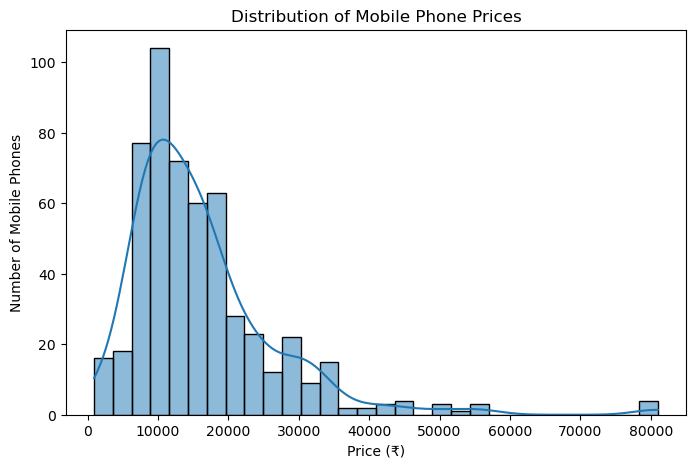

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Price", bins=30, kde=True)

plt.title("Distribution of Mobile Phone Prices")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Mobile Phones")
plt.show()

The mobile phone market in this dataset is dominated by budget and mid-range devices.
Prices are right-skewed, with most phones priced between ₹7,000 and ₹20,000 and a peak around ₹10,000.
Thin premium segment: Phones above ₹40,000 are rare, and the few near ₹80,000 are outliers, likely flagship models.
Few ultra-budget phones: Devices under ₹5,000 are a small niche.

## Ram VS Mobile Price

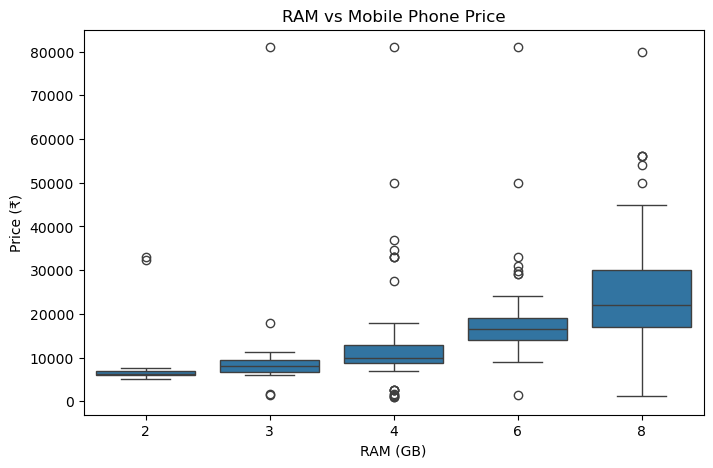

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="RAM", y="Price")

plt.title("RAM vs Mobile Phone Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (₹)")
plt.show()

## Battery and Price

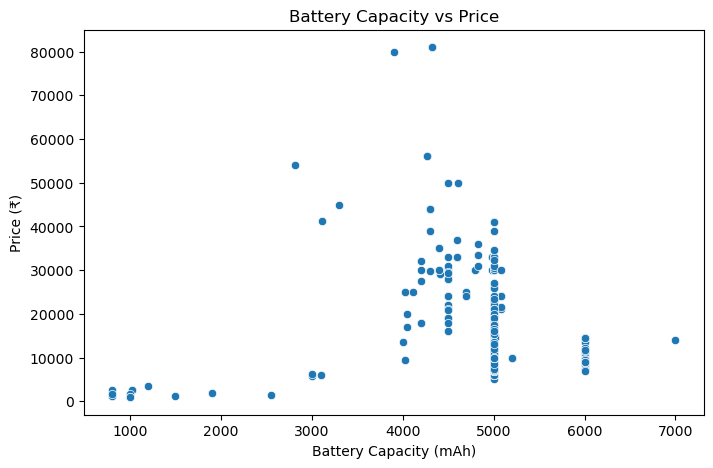

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Battery_", y="Price")

plt.title("Battery Capacity vs Price")
plt.xlabel("Battery Capacity (mAh)")
plt.ylabel("Price (₹)")
plt.show()

## Ram Vs Price

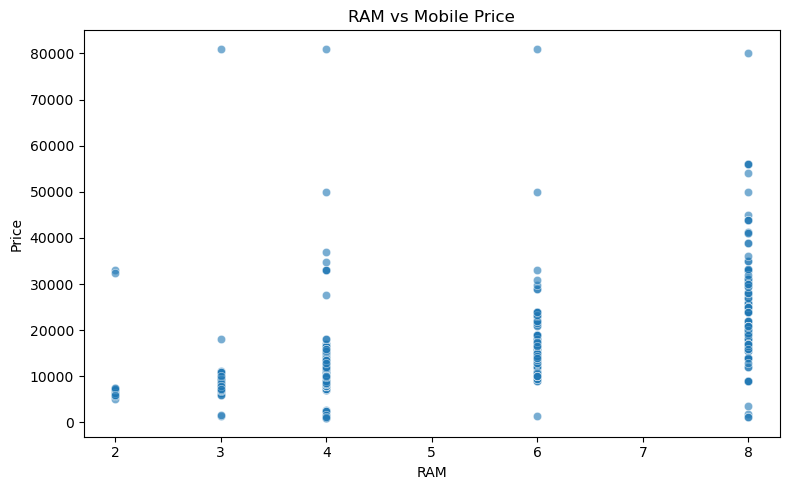

In [14]:
if "RAM" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x="RAM", y="Price", alpha=0.6)

    plt.title("RAM vs Mobile Price")
    plt.xlabel("RAM")
    plt.ylabel("Price")
    plt.tight_layout()
    plt.show()

## Average Price by Colour

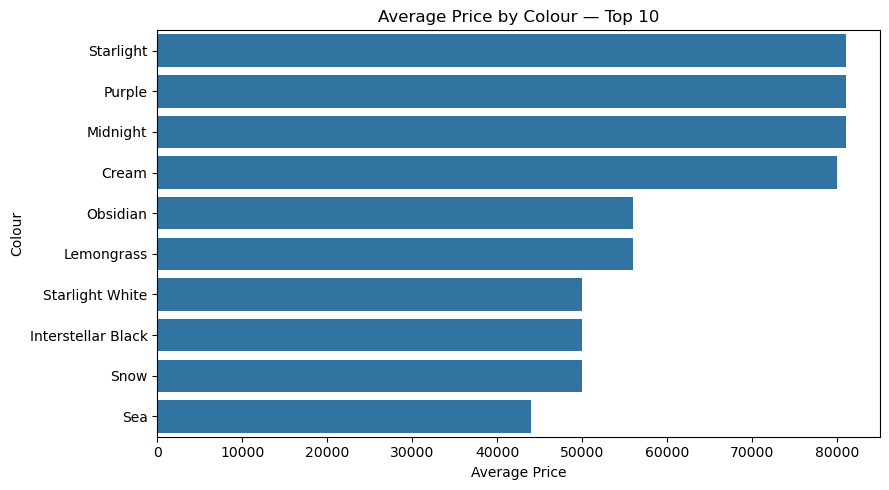

In [15]:
if "Colour" in df.columns:
    colour_price = (
        df.groupby("Colour", dropna=False)["Price"]
        .mean()
        .sort_values(ascending=False)
        .head(10)
        .reset_index()
    )

    plt.figure(figsize=(9, 5))
    sns.barplot(data=colour_price, x="Price", y="Colour")

    plt.title("Average Price by Colour — Top 10")
    plt.xlabel("Average Price")
    plt.ylabel("Colour")
    plt.tight_layout()
    plt.show()

## Numerical Correlation Heatmap

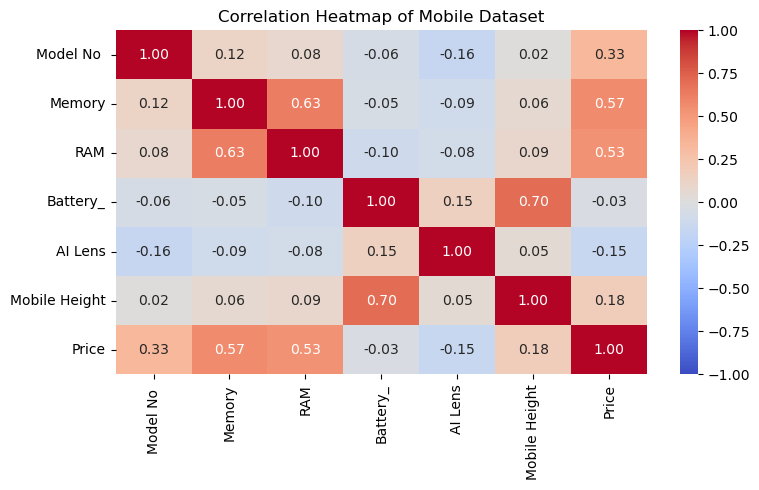

In [27]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 5))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Mobile Dataset")
plt.tight_layout()
plt.show()

## Feature Extraction and Selection

In [17]:
# Remove rows without target and split features from target
df = df.dropna(subset=["Price"]).copy()

# Remove ID-like columns if present
columns_to_drop = [
    col for col in df.columns
    if col.strip().lower() in ["id", "serial number", "unnamed: 0"]
]

X = df.drop(columns=["Price"] + columns_to_drop)
y = df["Price"]

# Remove columns that contain no information
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]
X = X.drop(columns=constant_cols)

print("Selected Features:")
print(X.columns.tolist())
print("\nTarget:", y.name)
print("X shape:", X.shape)
print("y shape:", y.shape)

Selected Features:
['Model No ', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_']

Target: Price
X shape: (541, 11)
y shape: (541,)


## Random Forest Model Building

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 432
Testing rows: 109


In [19]:
## Preprocessing and Random Forest Pipeline

In [20]:
# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build complete model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [21]:
# Predict test prices
y_pred = model.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"MAE: ₹{mae:,.2f}")
print(f"RMSE: ₹{rmse:,.2f}")
print(f"R² Score: {r2:.4f}")
print(f"R² Score (%): {r2 * 100:.2f}%")

MODEL EVALUATION RESULTS
------------------------
MAE: ₹1,959.25
RMSE: ₹4,767.83
R² Score: 0.8351
R² Score (%): 83.51%


## Feature Importance Graph

                         Feature  Importance
                     num__Memory    0.259635
                   num__Battery_    0.113641
                        num__RAM    0.111934
          cat__Front Camera_12MP    0.090271
                  num__Model No     0.083435
              num__Mobile Height    0.072044
 cat__Model_APPLE iPhone 14 Plus    0.039352
cat__Processor__Google Tensor G2    0.017940
           cat__Front Camera_0MP    0.017221
       cat__Model_Google Pixel 7    0.012204


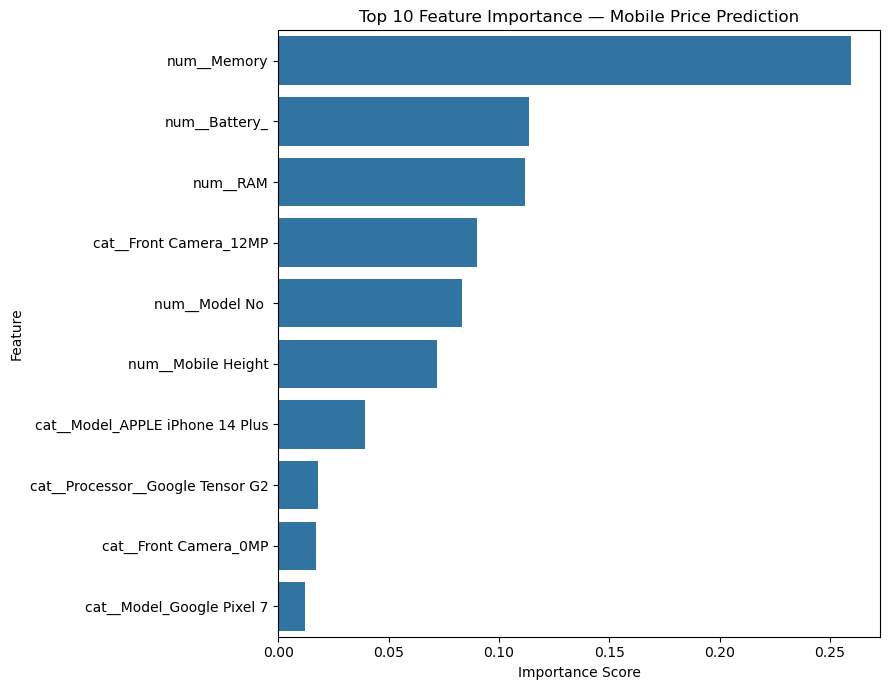

In [22]:
# Extract trained Random Forest
rf_model = model.named_steps["regressor"]

# Get transformed feature names
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Top 10 features
top_features = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print(top_features.to_string(index=False))

# Plot
plt.figure(figsize=(9, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance — Mobile Price Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Actual vs Predicted Price Graph

In [23]:
comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred
})

comparison["Absolute Error"] = abs(
    comparison["Actual Price"] - comparison["Predicted Price"]
)

display(comparison.head(10))

,Actual Price,Predicted Price,Absolute Error
0,8499,8518.965,19.965
1,6299,6622.280,323.280
2,19499,20189.685,690.685
3,10999,10885.755,113.245
4,12599,14657.115,2058.115
5,14499,14416.230,82.770
6,9999,9844.400,154.600
7,17999,16392.885,1606.115
8,29499,29757.025,258.025
9,9790,9179.970,610.030


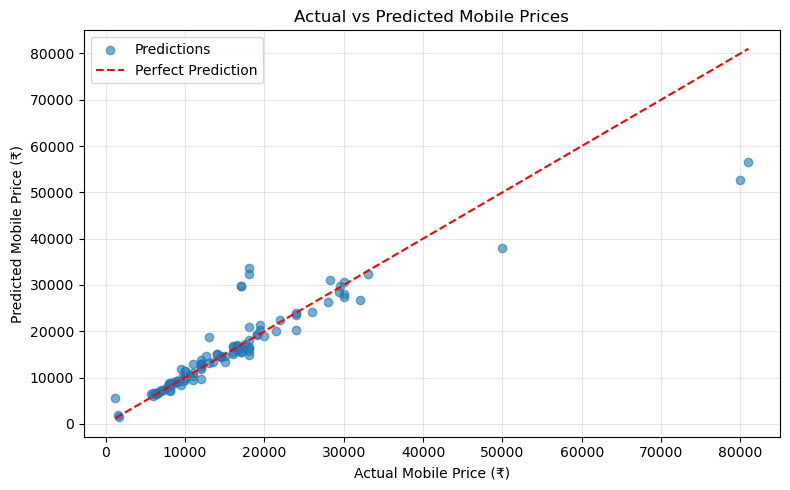

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6, label="Predictions")

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Mobile Price (₹)")
plt.ylabel("Predicted Mobile Price (₹)")
plt.title("Actual vs Predicted Mobile Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Test data par prediction
y_pred = model.predict(X_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Results
print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


Model Evaluation Results
------------------------
MAE: 1959.25
RMSE: 4767.83
R2 Score: 0.8351


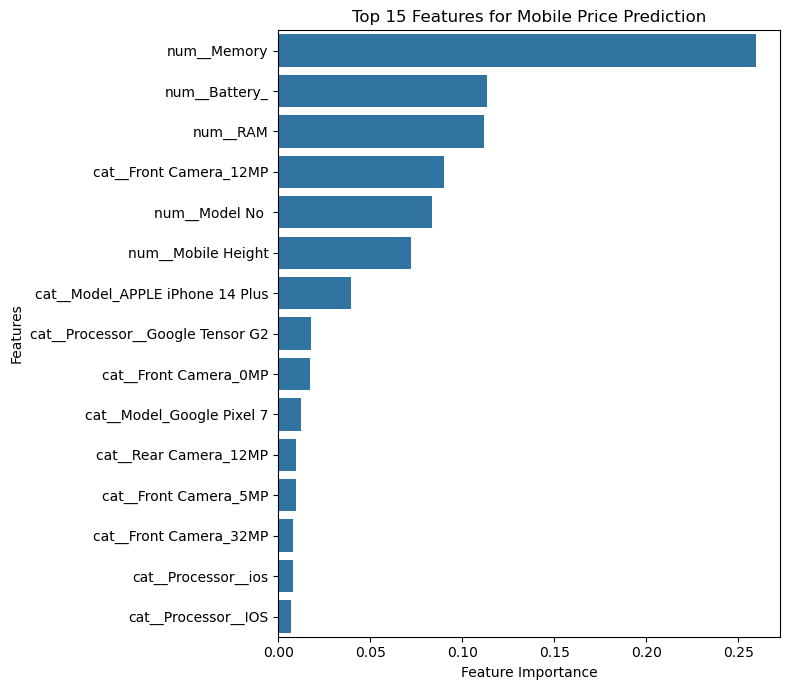

In [26]:
# Preprocessor se feature names nikalna
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Random Forest se importance values nikalna
importances = model.named_steps["regressor"].feature_importances_

# DataFrame banana
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Highest importance pehle dikhana
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

# Top 15 features ka graph
top_features = importance_df.head(15)

plt.figure(figsize=(8, 7))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features for Mobile Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()
